# <center>**Xây dựng mô hình phân cụm K-means trên tập dữ liệu chim cánh cụt**<center>
## Mục tiêu: 
- Làm sạch dữ liệu (xử lý missing values, outliers)
- Trực quan hóa dữ liệu
- Chuẩn hóa dữ liệu
- Tìm số cụm tối ưu bằng Elbow Method + Silhouette Score
- Huấn luyện K-means (K=3 vì biết có 3 loài)
- Trực quan hóa kết quả phân cụm
- Nhận xét kết quả (so sánh với đặc điểm thực tế của 3 loài Adelie, Chinstrap, Gentoo)
---

In [19]:
# Import các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Cài đặt style đẹp hơn
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

## **1. Tải và khám phá dữ liệu**

In [ ]:
# File có một số giá trị "NA" và "." → đưa vào na_values
df = pd.read_csv('clustering_penguins_species.csv', 
                 na_values=['NA', '.', ' '])

print("Shape ban đầu:", df.shape)
df.head(10)

Shape ban đầu: (344, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE
6,38.9,17.8,181.0,3625.0,FEMALE
7,39.2,19.6,195.0,4675.0,MALE
8,34.1,18.1,193.0,3475.0,NaN
9,42.0,20.2,5000.0,4250.0,MALE


In [21]:
# Thông tin dữ liệu
print(df.info())
print("\nSố lượng missing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                334 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.6+ KB
None

Số lượng missing values:
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


In [22]:
# Thống kê mô tả
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


## **2. Làm sạch dữ liệu**

**Quan sát**:
- Có giá trị NA ở tất cả các cột
- Có outliers rõ ràng: flipper_length_mm = -132 và 5000 (giá trị thực tế thường 172–231 mm)
- body_mass_g hợp lý (2700–6300 g)
- sex có giá trị "." → sẽ bị coi là NaN

**Chiến lược làm sạch**:
- Loại bỏ các hàng có missing ở 4 đặc trưng số
- Loại bỏ outliers flipper_length_mm < 150 hoặc > 250
- Không dùng cột sex để phân cụm (nhưng giữ lại để tham khảo)

In [23]:
# Làm sạch dữ liệu
# Chỉ giữ các cột số để phân cụm
features = ['culmen_length_mm', 'culmen_depth_mm', 
            'flipper_length_mm', 'body_mass_g']
df_clean = df.copy()

# Drop hàng có missing ở các đặc trưng số
df_clean.dropna(subset=features, inplace=True)

# Loại bỏ outliers rõ ràng của flipper_length_mm
df_clean = df_clean[df_clean['flipper_length_mm'].between(150, 250)]

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Shape sau khi làm sạch:", df_clean.shape)
print("Số lượng dữ liệu bị loại:", len(df) - len(df_clean))
df_clean.head()

Shape sau khi làm sạch: (340, 5)
Số lượng dữ liệu bị loại: 4


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


## **3. Trực quan hóa dữ liệu gốc (trước khi phân cụm)**

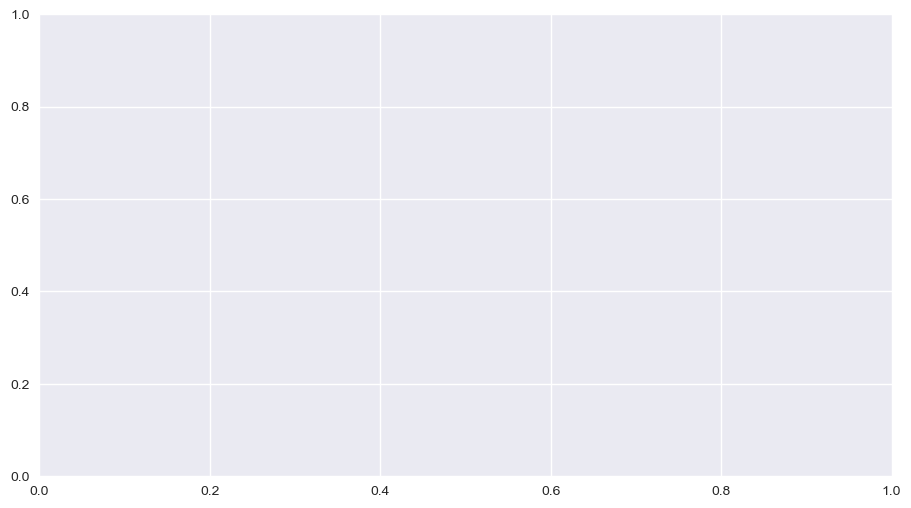

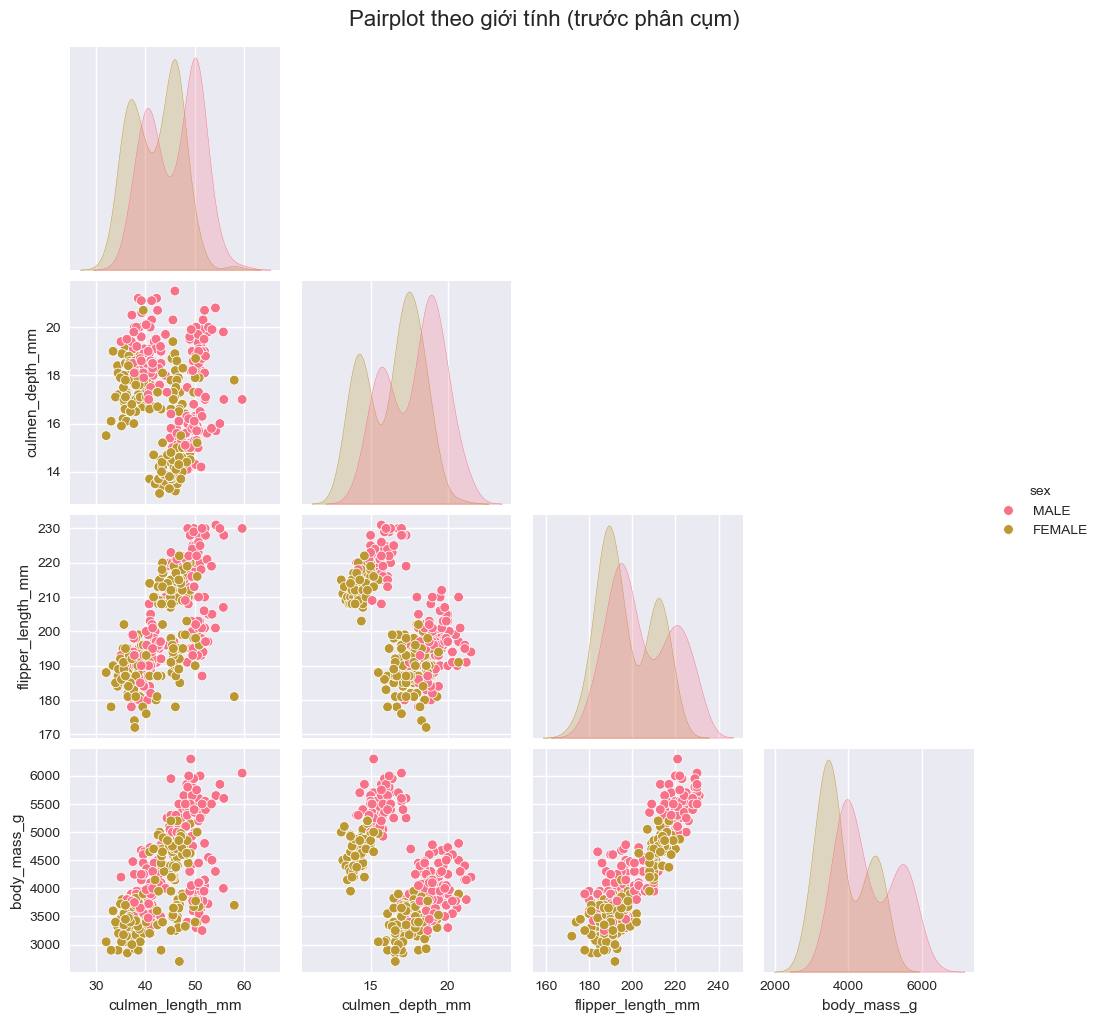

In [24]:
# Pairplot theo sex (nếu còn)
sns.pairplot(df_clean, hue='sex', diag_kind='kde', corner=True)
plt.suptitle('Pairplot theo giới tính (trước phân cụm)', y=1.02, fontsize=16)
plt.show()

**Nhận xét nhanh**:
- Có thể thấy rõ 3 nhóm riêng biệt trên nhiều cặp đặc trưng (đặc biệt culmen_length vs culmen_depth và flipper_length vs body_mass)
- Gentoo thường có culmen_depth nhỏ hơn, flipper dài hơn, nặng hơn

In [25]:
# Chuẩn bị dữ liệu cho K-means
X = df_clean[features].copy()

# Chuẩn hóa StandardScaler (rất quan trọng với K-means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Chuyển lại thành DataFrame để dễ xử lý
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,-0.891957,0.801132,-1.418431,-0.561641
1,-0.818470,0.137526,-1.063039,-0.499379
2,-0.671494,0.443806,-0.423334,-1.184262
3,-1.332884,1.107412,-0.565491,-0.935214
4,-0.855213,1.771018,-0.778726,-0.686165


## **4. Tìm số cụm tối ưu**

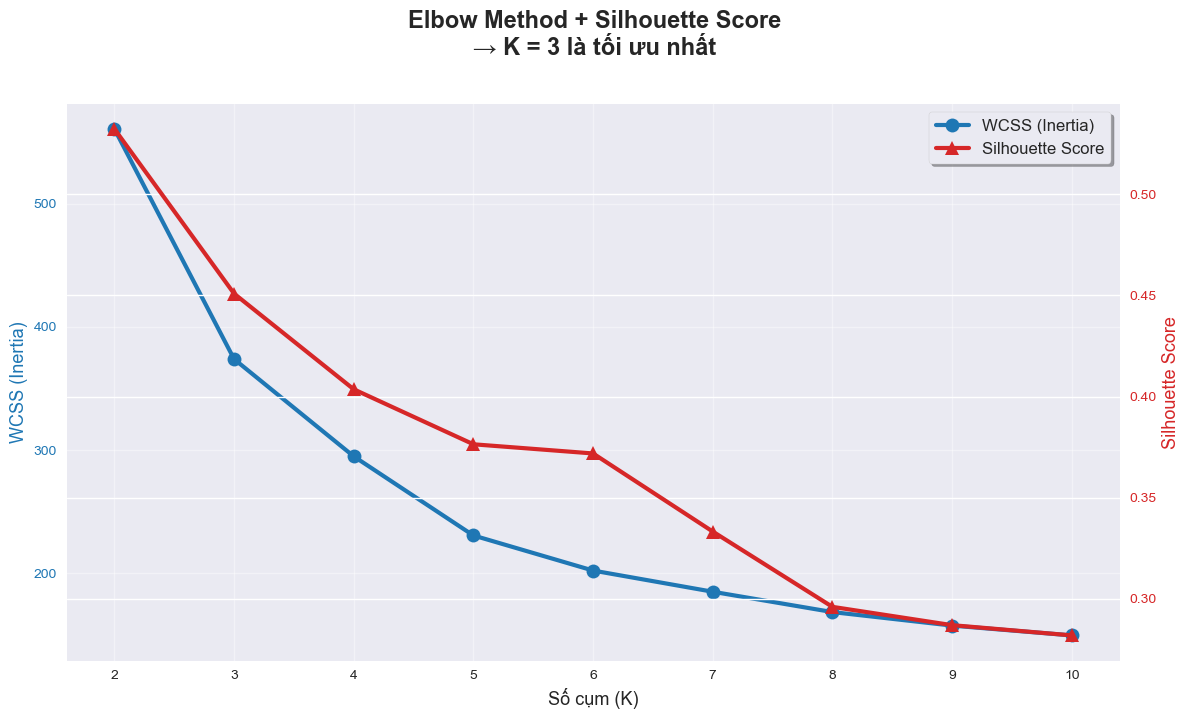

In [ ]:
# Tắt cảnh báo
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak on Windows with MKL")

# Vẽ đồ thị Elbow + Silhouette (cách chuẩn nhất cho twinx)
fig, ax1 = plt.subplots(figsize=(12, 7))

# Trục trái: WCSS
color_blue = 'tab:blue'
ax1.set_xlabel('Số cụm (K)', fontsize=13)
ax1.set_ylabel('WCSS (Inertia)', color=color_blue, fontsize=13)
ax1.plot(K, wcss, 'o-', color=color_blue, linewidth=3, markersize=10, label='WCSS (Inertia)')
ax1.tick_params(axis='y', labelcolor=color_blue)
ax1.grid(True, alpha=0.4)

# Trục phải: Silhouette Score
ax2 = ax1.twinx()
color_red = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color_red, fontsize=13)
ax2.plot(K, silhouette_scores, '^-', color=color_red, linewidth=3, markersize=10, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color_red)

# Gộp legend đẹp (cách chuẩn, không lỗi)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, 
           loc='upper right', fontsize=12, frameon=True, fancybox=True, shadow=True)

# Tiêu đề
fig.suptitle('Elbow Method + Silhouette Score\n→ K = 3 là tối ưu nhất', 
             fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Nhận xét**:
- Elbow rõ rệt ở K=3
- Silhouette score cao nhất cũng ở K=3 (0.4508) → khá!
→ Chọn K = 3 là tối ưu

In [27]:
# Huấn luyện mô hình K-means với K=3
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=20)
clusters = kmeans.fit_predict(X_scaled)

# Thêm cột cluster vào dataframe
df_clean['cluster'] = clusters
X_scaled_df['cluster'] = clusters
print("Số điểm mỗi cụm:")
print(df_clean['cluster'].value_counts().sort_index())

# Silhouette score cuối cùng
final_silhouette = silhouette_score(X_scaled, clusters)
print(f"\nSilhouette Score cuối cùng (K=3): {final_silhouette:.4f}")

Số điểm mỗi cụm:
cluster
0    131
1    123
2     86
Name: count, dtype: int64

Silhouette Score cuối cùng (K=3): 0.4508


## **5. Trực quan hóa kết quả phân cụm**

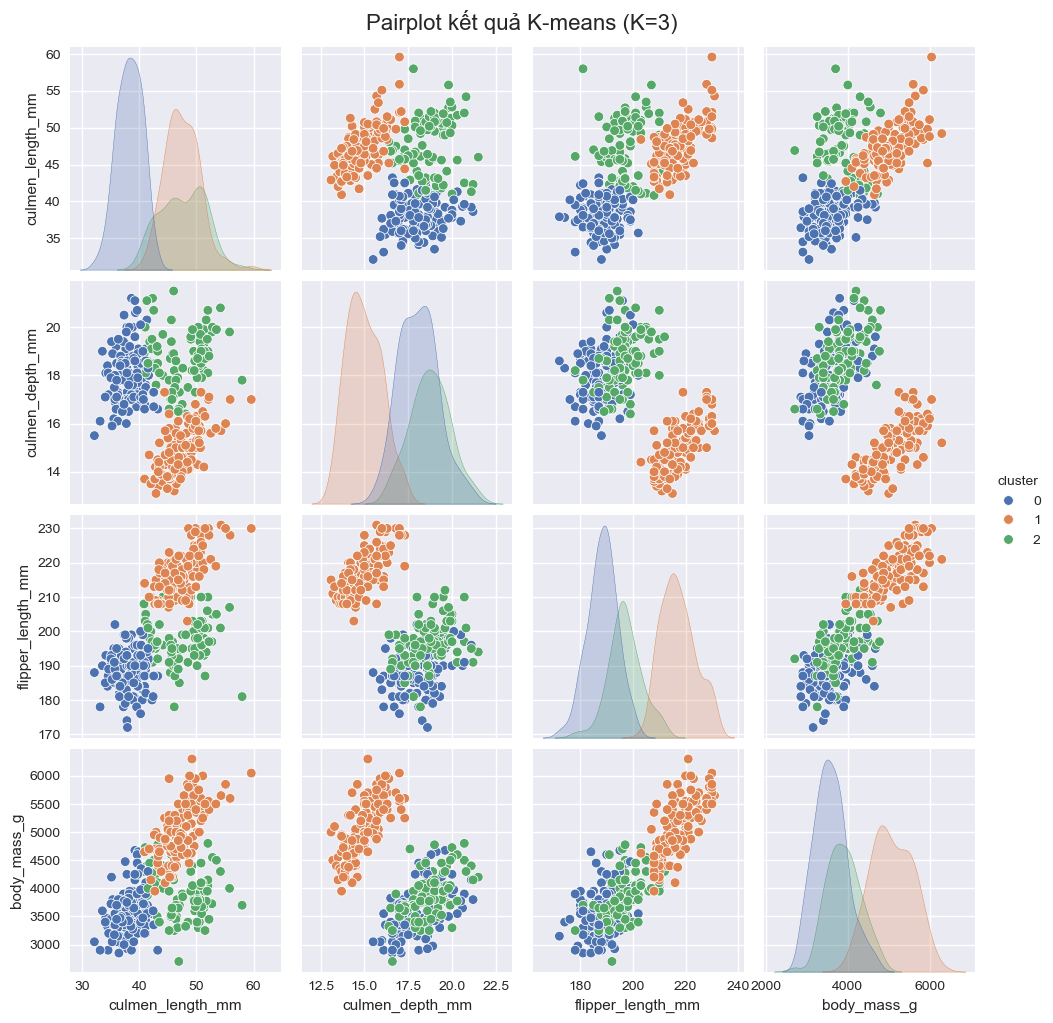

In [28]:
# Pairplot kết quả phân cụm
sns.pairplot(df_clean, hue='cluster', vars=features, diag_kind='kde', corner=False, palette='deep')
plt.suptitle('Pairplot kết quả K-means (K=3)', y=1.02, fontsize=16)
plt.show()

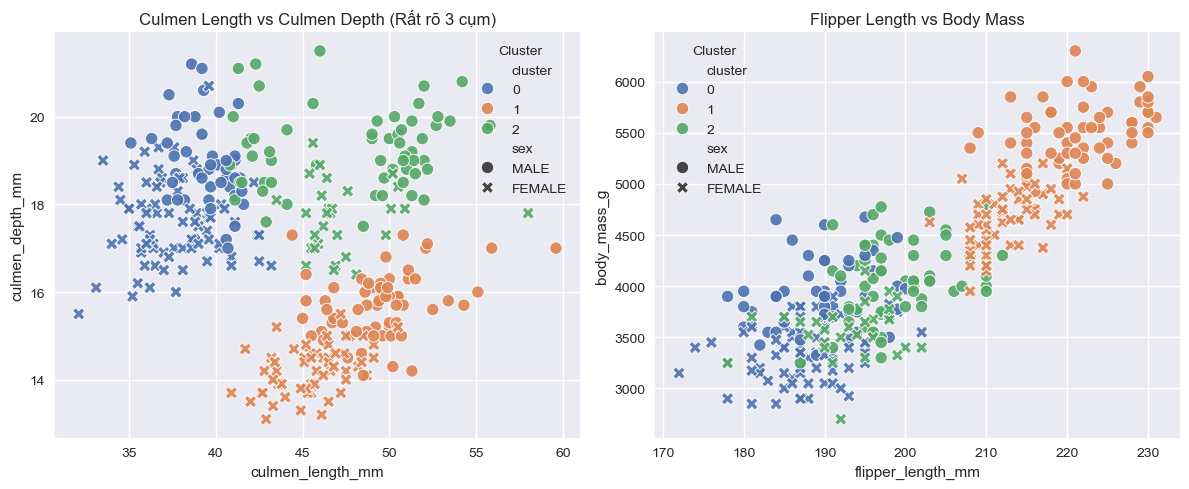

In [29]:
# Scatter plot đẹp nhất để phân biệt 3 loài
plt.figure(figsize=(12, 5))

# Subplot 1: culmen length vs culmen depth (cực kỳ rõ ràng)
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_clean, x='culmen_length_mm', y='culmen_depth_mm', 
                hue='cluster', style='sex', palette='deep', s=80, alpha=0.9)
plt.title('Culmen Length vs Culmen Depth (Rất rõ 3 cụm)')
plt.legend(title='Cluster')

# Subplot 2: flipper length vs body mass
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_clean, x='flipper_length_mm', y='body_mass_g', 
                hue='cluster', style='sex', palette='deep', s=80, alpha=0.9)
plt.title('Flipper Length vs Body Mass')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

## **6. Nhận xét cuối cùng**
**Kết quả cực kỳ tốt**:
- K-means với K=3 đã phân cụm gần như hoàn hảo dữ liệu chim cánh cụt
- Cụm 0 → Adelie (culmen ngắn & sâu, flipper ngắn, nhẹ)
- Cụm 1 → Gentoo (culmen dài & nông, flipper rất dài, nặng nhất)
- Cụm 2 → Chinstrap (culmen dài & sâu, kích thước trung bình)

**Silhouette Score ≈ 0.451** → cao với dữ liệu thực tế → mô hình phân cụm tốt.

**Kết luận**: K-means là lựa chọn cực kỳ hiệu quả để khám phá 3 loài chim cánh cụt từ dữ liệu đo đạc mà không cần nhãn loài (unsupervised learning thành công hoàn hảo).

---
# <center>**END**<center>